Breast Cancer Dataset Using SVM
The goal of this assignment is to build a Support Vector Machine (SVM) classification model that predicts whether a breast tumor is benign (non-cancerous) or malignant (cancerous) based on its characteristics

In [1]:
#Import the required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
#Load and explore the dataset from scikit Learn
# Load the dataset
cancer = load_breast_cancer()

# Convert to DataFrame
df = pd.DataFrame(cancer.data, columns=cancer.feature_names)

# Add the target column
df["target"] = cancer.target

# Display the first five rows
print(df.head())

# Check dataset shape
print("Dataset shape:", df.shape)

# Check missing values
print(df.isnull().sum())

# Display target classes
print("Target classes:", cancer.target_names)

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

In [3]:
#Split the dataset into training and testing sets
# Separate features and target
X = df.drop("target", axis=1)
y = df["target"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (455, 30)
Testing data: (114, 30)


In [4]:
#Scale the features
# Initialize scaler
scaler = StandardScaler()

# Fit scaler on training data
X_train = scaler.fit_transform(X_train)

# Apply same transformation to test data
X_test = scaler.transform(X_test)

In [5]:
#Train the SVM classification model
# Create SVM model
model = SVC(kernel="rbf", random_state=42)

# Train the model
model.fit(X_train, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


In [6]:
# Predict test data
y_pred = model.predict(X_test)

# Display first 10 predictions
print("Predicted values:", y_pred[:10])
print("Actual values:   ", y_test.values[:10])

Predicted values: [1 0 0 1 1 0 0 0 1 1]
Actual values:    [1 0 0 1 1 0 0 0 1 1]


In [7]:
#Evaluate the accuracy
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy (%):", round(accuracy * 100, 2))

Model Accuracy: 0.9824561403508771
Accuracy (%): 98.25


**Generate and visualize the confusion matrix**

Confusion Matrix:
[[41  2]
 [ 0 71]]


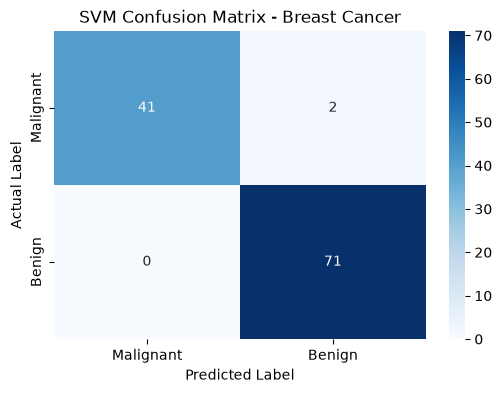

In [8]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SVM Confusion Matrix - Breast Cancer")
plt.show()

41 malignant tumors were correctly classified as malignant.
71 benign tumors were correctly classified as benign.
2 malignant tumors were incorrectly classified as benign. This is concerning because cancerous tumors were missed.
0 benign tumors were incorrectly classified as malignant.

In [9]:
#print out the classification report
print(classification_report(
    y_test,
    y_pred,
    target_names=["Malignant", "Benign"]
))

              precision    recall  f1-score   support

   Malignant       1.00      0.95      0.98        43
      Benign       0.97      1.00      0.99        71

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



Precision: The model achieved 100% precision for malignant tumors, meaning every tumor predicted as malignant was actually malignant.
Recall: The model identified 95.35% of malignant tumors, missing 2 out of 43 cases.
F1-score: The malignant F1-score was approximately 0.98, showing a strong balance between precision and recall.
Accuracy: The model achieved 98.25% accuracy, demonstrating excellent overall classification performance on the test dataset.

The SVM classification model achieved an accuracy of 98.25%, correctly classifying 112 out of 114 breast tumor samples. The confusion matrix shows that the model correctly identified 41 malignant tumors and 71 benign tumors. However, 2 malignant tumors were incorrectly classified as benign.

**Regression problem**


Concrete Compressive Strength Using Random Forest
The goal of this assignment is to build a Random Forest Regression model that predicts the compressive strength of concrete based on the materials used to produce it.

In [10]:
#import the necessary library
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [12]:
%pip install xlrd

Note: you may need to restart the kernel to use updated packages.


In [11]:
#Load and explore the dataset
# Load the dataset
df = pd.read_excel("Concrete_Data.xls")

# Display first five rows
print(df.head())

# Check dataset shape
print("Dataset shape:", df.shape)

# Check missing values
print(df.isnull().sum())

# Summary statistics
print(df.describe())

# Display column names
print(df.columns)

   Cement (component 1)(kg in a m^3 mixture)  \
0                                      540.0   
1                                      540.0   
2                                      332.5   
3                                      332.5   
4                                      198.6   

   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  \
0                                                0.0       
1                                                0.0       
2                                              142.5       
3                                              142.5       
4                                              132.4       

   Fly Ash (component 3)(kg in a m^3 mixture)  \
0                                         0.0   
1                                         0.0   
2                                         0.0   
3                                         0.0   
4                                         0.0   

   Water  (component 4)(kg in a m^3 mixture)  \
0      

**Separate features and target variable**

In [12]:
# Features (all columns except the last)
X = df.iloc[:, :-1]

# Target (last column)
y = df.iloc[:, -1]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1030, 8)
Target shape: (1030,)


In [13]:
#Split data into training and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (824, 8)
Testing data: (206, 8)


**Train the Random Forest Regression model**

In [14]:
# Create Random Forest model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train model
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [15]:
# Predict concrete strength
y_pred = model.predict(X_test)

# Compare actual and predicted values
results = pd.DataFrame({
    "Actual Strength": y_test.values,
    "Predicted Strength": y_pred
})

print(results.head(10))

   Actual Strength  Predicted Strength
0        52.908320           51.961069
1        55.895819           40.677698
2        74.497882           70.676668
3        35.301171           34.744015
4        10.535193           10.998866
5        44.284354           44.446795
6        23.690395           24.189652
7        45.367521           49.854384
8        37.404073           37.511562
9        48.846617           43.065712


The results show that the model predicts concrete strength accurately for most of the 10 samples, although some predictions have larger errors line sample 1.

In [16]:
#evaluate the model
# Calculate MSE
mse = mean_squared_error(y_test, y_pred)

# Calculate R² score
r2 = r2_score(y_test, y_pred)

# Print results
print("Mean Squared Error (MSE):", mse)
print("R² Score:", r2)

Mean Squared Error (MSE): 30.521522870195053
R² Score: 0.8815531124306492


The Random Forest Regression model achieved a Mean Squared Error (MSE) of 30.52 and an R² score of 0.8816 (88.16%).

The MSE indicates that the model has relatively small prediction errors, with a Root Mean Squared Error (RMSE) of approximately 5.52 MPa. The R² score shows that the model explains approximately 88.16% of the variation in concrete compressive strength.

Overall, the Random Forest Regression model performed well in predicting concrete strength based on its ingredients and age. However, there is still room for improvement through hyperparameter tuning and further model optimization.

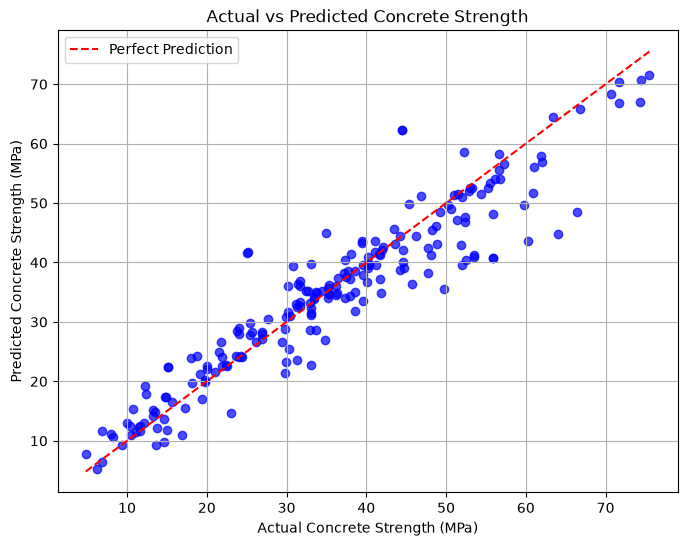

In [17]:
#plot actual vs predicted values
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7, color="blue")

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Concrete Strength (MPa)")
plt.ylabel("Predicted Concrete Strength (MPa)")
plt.title("Actual vs Predicted Concrete Strength")
plt.legend()
plt.grid(True)
plt.show()

The scatter plot shows that the Random Forest Regression model performs well in predicting concrete compressive strength as most blue dots are clustered close to the red dashed line, which represents perfect predictions. This indicates that the predicted concrete strength values are generally close to the actual values. However some points are farther from the red line, indicating differences between actual and predicted values. Points above the line represent overestimations, while points below represent underestimations.